Imports

In [94]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

Train and test split

In [95]:
# Training and Test Data Splitter
def train_test_split (df, i=0) :
    train = df.sample(frac=0.8, random_state=i)
    test = df.drop(train.index)
    xtrain = np.array(train.drop(columns=[0]))
    xtest = np.array(test.drop(columns=[0]))
    ytrain = np.array(train[0])
    ytest = np.array(test[0])
    trainpos = train.index.to_numpy()
    testpos = test.index.to_numpy()
    return xtrain, xtest, ytrain, ytest, trainpos, testpos


Kernel Functions

In [96]:
def guass_ker_matrix(x1, x2):
    x1sq = np.sum(x1 ** 2, axis=1)[:, None]  # (n1, 1)
    x2sq = np.sum(x2 ** 2, axis=1)[None, :]  # (1, n2)
    num = x1sq + x2sq - 2 * (x1 @ x2.T)
    return (num)
def guass_kern (x1, x2, c=1, **kwargs):
    x1sq = np.sum(x1 ** 2, axis=1)[:, None]  # (n1, 1)
    x2sq = np.sum(x2 ** 2, axis=1)[None, :]  # (1, n2)
    num = x1sq + x2sq -2*(x1@x2.T)
    K = np.exp(-c * (num))
    return K
def poly_kern_matrix (x1, x2):
    return (x1@x2.T)
def poly_kern (x1, x2, d=1, **kwargs) :
    return (x1@x2.T) ** d

def block_kern (x1, x2, n1, n2, kernel_func, bSize = 250, **kwargs):
    noBlocks1 = int(np.ceil(n1 / bSize))
    noBlocks2 = int(np.ceil(n2 / bSize))
    blocks1 = []
    blocks2 = []
    for b in range(noBlocks1):
        start = b * bSize
        end = min((b + 1) * bSize, n1)
        blocks1.append((start, end))

    for b in range(noBlocks2):
        start = b * bSize
        end = min((b + 1) * bSize, n2)
        blocks2.append((start, end))
    K = np.zeros((n1, n2))
    for iStart, iEnd in blocks1:
        for jStart, jEnd in blocks2:
            K[iStart:iEnd, jStart:jEnd] = kernel_func(x1[iStart:iEnd, :], x2[jStart:jEnd, :], **kwargs)
    return K


def full_kern (x1, kernel_func, x2=None, bSize=250, **kwargs) :
    x1 = np.array(x1)
    n1 =len(x1)
    if x2 is None :
        x2 = x1
        n2 = n1
    else:
        x2 = np.array(x2)
        n2 = len(x2)
    if n1 > bSize:
        K = block_kern(x1, x2, n1, n2, kernel_func=kernel_func, **kwargs)
    else :
        K = kernel_func(x1, x2, **kwargs) #Return full Kernel
    return K

Confusion Matrix functions

In [97]:
def confusion_matrix(y, yhat, Classes):
    confMatrix = np.zeros((len(Classes), len(Classes)))
    digitCounts = np.zeros(len(Classes))
    for i in range((len(y))):
        digitCounts[int(y[i])] = digitCounts[int(y[i])] + 1
        if yhat[i] != y[i]:
            confMatrix[int(y[i]), int(yhat[i])] = confMatrix[int(y[i]), int(yhat[i])] + 1
    for i in range((len(Classes))):
        if digitCounts[i] > 0:
            confMatrix[i, :] = confMatrix[i,:]/digitCounts[i]
    return confMatrix

def confusion_matrix_df(confMatrix, Classes):
    row, col,_ = confMatrix.shape
    df = np.empty((row, col), dtype=object)
    for i in range(row):
        for j in range(col):
            me = confMatrix[i, j,0]
            sd = confMatrix[i, j,1]
            if me != 0:
                me = float(f'{me:.{4}g}')
                me = np.format_float_scientific(me, precision=4, exp_digits=2, trim='k')
                me = me.replace('e', 'x10')
            if sd != 0:
                sd = float(f'{sd:.{4}g}')
                sd = np.format_float_scientific(sd, precision=4, exp_digits=2, trim='k')
                sd = sd.replace('e', 'x10')
            df[i,j] = f'{me}±{sd}'
    return pd.DataFrame(df, index=Classes, columns=Classes)

Two class classifier functions

In [ ]:
def two_class_ker_perc_pred (alpha, x, y, target_class, K_precal_test):
    y_pred = []
    total_errors = 0
    for i in range(len(x)):
        K = K_precal_test[i, :]
        # K = K_precal[:,i]
        K = np.array(K)
        if (alpha @ K) >= 0:
            y_hat = 1
        else:
            y_hat = -1
        if y_hat != y[i]:
            total_errors = total_errors + 1
        y_pred.append(y_hat)
    total_errors = total_errors / len(x)
    return y_pred, total_errors

def two_class_ker_perc_full (df, kernel_func, target_class, epoch = 1, K_precal_train = None, split = None, trainhelper=False, **kwargs):
    if split is None : #If no prespecified train test splits given make from scratch
        xtrain, xtest, ytrain, ytest, _, _ = train_test_split(df)
    else : #Otherwise if prespecified train test splits given unpack
        xtrain, xtest, ytrain, ytest = split
    ytrain = np.where(ytrain == target_class, 1, -1)  # Change ytrain 1 = target_class, -1 otherwise
    ytest = np.where(ytest == target_class, 1, -1)  # Same for ytest
    epoch_threshold = 3
    no_improvement_count = 0
    min_epoch_errors = np.inf
    alpha = np.zeros(len(xtrain))
    best_alpha = alpha.copy()
    if K_precal_train is None : #Checks to see if a precalculated train Kernel has been passed in, if not calculate
        K_precal_train = full_kern(xtrain, kernel_func=kernel_func, **kwargs)
    total_errors_train = 0
    for e in range(epoch) :
        epoch_errors = 0
        #print(f"Epoch {e}, Class = {target_class}")
        for i in range(len(xtrain)) :
            # alpha_i = alpha[:i]  # all previous alpha's
            # K = K_precal_train[:i, i]
            # if (alpha_i @ K) >= 0:
            K = K_precal_train[:, i]
            if (alpha @ K) >= 0:
                y_hat = 1
            else :
                y_hat = -1
            if y_hat != ytrain[i] :
                alpha[i] = alpha[i] + ytrain[i]
                epoch_errors = epoch_errors + 1
                total_errors_train = total_errors_train + 1
        if epoch_errors < min_epoch_errors:
            min_epoch_errors = epoch_errors
            no_improvement_count = 0
            best_alpha = alpha.copy()
        else :
            no_improvement_count = no_improvement_count + 1
        if no_improvement_count >= epoch_threshold:
            #print(f"Stopped early at epoch {e} for class {target_class}")
            break
    total_errors_train = min_epoch_errors / len(xtrain)

    alpha = best_alpha.copy()
    if trainhelper == False: #If function is being called as a two class classifier complete the predictoin step, otherwise skip predictions
        K_precal_test = full_kern(xtest, kernel_func=kernel_func, x2=xtrain, **kwargs)
        y_pred_test, total_errors_test = two_class_ker_perc_pred(alpha, xtest, ytest, target_class, K_precal_test)
        return alpha, total_errors_train, y_pred_test, total_errors_test
    return alpha, total_errors_train, None, None #If function being called to do training step in another algorithm only return training outputs


k class classifier one vs rest functions

In [ ]:
def k_class_one_vs_rest_ker_perc_pred (alpha, x, y, k_classes, K_precal_test, confusion=False):
    y_pred = []
    total_errors = 0
    for i in range(len(x)) :
        y_hat = []
        K = K_precal_test[i, :]
        # K = K_precal[:,i)
        K = np.array(K)
        for j, k in enumerate (k_classes) :
            y_hat.append(alpha[j] @ K)
        y_pred.append(k_classes[y_hat.index(max(y_hat))])
        if y_pred[i] != y[i]:
            total_errors = total_errors + 1
    if confusion == True:
        confMatrix = confusion_matrix(y, y_pred, k_classes)
    else:
        confMatrix = None
    total_errors = total_errors/len(x)
    return y_pred, total_errors, confMatrix

def k_class_one_vs_rest_ker_perc (df, kernel_func, k_classes, epoch=1, split=None, K_precal_train = None, K_precal_test = None, confusion=False, **kwargs):
    if split is None :
        xtrain, xtest, ytrain, ytest, _, _ = train_test_split(df) #create test train splits
    else :
        xtrain, xtest, ytrain, ytest = split
    alpha, y_pred_test, train_errors, test_erros = [], [], [], []
    if K_precal_train is None:
        K_precal_train = full_kern(xtrain, kernel_func=kernel_func, **kwargs) #Precalculate the Kernel Matrix
    if K_precal_test is None:
        K_precal_test = full_kern(xtest, kernel_func=kernel_func, x2=xtrain, **kwargs)
    for k in k_classes : #Loop through the k classes
        split = (xtrain, xtest, ytrain.copy(), ytest.copy()) #Store new dataset with y {1,-1} labels
        alpha_k, train_errors_k, _, _ = two_class_ker_perc_full(None, kernel_func, k, epoch=epoch, K_precal_train=K_precal_train, split = split, trainhelper=True) #Train 2 class classifier, (k vs rest)
        alpha.append(alpha_k) #Add k vs rest alpha values to alpha list
        train_errors.append(train_errors_k)
    y_pred_test, test_errors, confMatrix = k_class_one_vs_rest_ker_perc_pred(alpha, xtest, ytest, k_classes, K_precal_test, confusion)
    me_train = np.mean(train_errors)
    me_test = np.mean(test_errors)
    return alpha, y_pred_test, me_train, me_test, train_errors, test_errors, confMatrix

k class classifier one vs one functions

In [ ]:
def k_class_one_vs_one_ker_perc_pred (alpha, x, y, k_classes, K_precal_test, confusion=False):
    y_pred = []
    total_errors = 0
    for j in range(len(x)):
        y_hat = np.zeros(len(k_classes))
        for i, a in enumerate(k_classes):
            for k, b in enumerate (k_classes):
                if k<i :
                    K_test_pair = K_precal_test[(i,k)]["K"]
                    testPos = K_precal_test[(i,k)]["testPos"]
                    if j not in testPos:
                        continue
                    K_test_pair_jrow = np.where(testPos == j)[0][0]
                    K = K_test_pair[K_test_pair_jrow, :]
                    K = np.array(K)
                    if (alpha[(i,k)] @ K) >= 0:
                        y_hat[i] = y_hat[i]+1
                    else:
                        y_hat[k] = y_hat[k]+1
        y_pred.append(k_classes[np.argmax(y_hat)])
        if y_pred[j] != y[j]:
            total_errors = total_errors + 1
    if confusion == True:
        confMatrix = confusion_matrix(y, y_pred, k_classes)
    else:
        confMatrix = None
    total_errors = total_errors/len(x)
    return y_pred, total_errors, confMatrix

def k_class_one_vs_one_ker_perc(df, kernel_func, k_classes, epoch=1, split=None, K_precal_train = None, K_precal_test = None, confusion=False, **kwargs):
    if split is None:
        xtrain, xtest, ytrain, ytest, _, _ = train_test_split(df)  # create test train splits
    else:
        xtrain, xtest, ytrain, ytest = split
    alpha, K_train_pairs, K_test_pairs = {}, {}, {}
    y_pred_test, train_errors, test_errors = [], [], []
    if K_precal_train is None:
        K_precal_train = full_kern(xtrain, kernel_func=kernel_func, **kwargs) #Precalculate the Kernel Matrix
    if K_precal_test is None:
        K_precal_test = full_kern(xtest, kernel_func=kernel_func, x2=xtrain, **kwargs)
    for i in k_classes :
        for k  in k_classes:
            if k < i :
                trainPos = np.where((ytrain == i)|((ytrain == k)))[0]
                ytrain_pair = ytrain[trainPos]
                xtrain_pair = xtrain[trainPos]
                testPos = np.where((ytest == i) | ((ytest == k)))[0]
                ytest_pair = ytest[testPos]
                xtest_pair = xtest[testPos]
                split = (xtrain_pair, None, ytrain_pair, None)
                K_train_pair = K_precal_train[np.ix_(trainPos, trainPos)]  # Precalculate the Kernel Matrix
                # K_test_pair  = K_precal_test[:,trainPos]
                K_test_pair = K_precal_test[np.ix_(testPos, trainPos)]
                alpha_ik, train_errors_k, _, _ = two_class_ker_perc_full(None, kernel_func, i, epoch=epoch,K_precal_train=K_train_pair,split=split, trainhelper=True)  # Train 2 class classifier, (k vs rest)
                alpha[(i,k)] = alpha_ik  # Add k vs rest alpha values to alpha list
                K_train_pairs[(i, k)] = K_train_pair
                K_test_pairs[(i,k)] = {"K" : K_test_pair, "testPos": testPos}
                train_errors.append(train_errors_k)
    y_pred_test, test_errors, confMatrix = k_class_one_vs_one_ker_perc_pred(alpha, xtest, ytest, k_classes, K_test_pairs, confusion)
    me_train = np.mean(train_errors)
    me_test = np.mean(test_errors)
    return alpha, y_pred_test, me_train, me_test, train_errors, test_errors, confMatrix

Cross Validation Function

In [ ]:
def cross_validation(xtrain, ytrain, folds, algorithm_func, kernel_func, paramlist, k_classes, epoch_lim=1, **kwargs):
    positions = np.arange(len(xtrain))
    foldPositions = np.array_split(positions, folds)

    K_precal = {p: full_kern(xtrain, kernel_func=kernel_func, d=p, c=p) for p in paramlist}

    results = np.zeros((folds, len(paramlist), 1))
    for j, p in enumerate(paramlist):
        K_train_full = K_precal[p]

        for i in range(folds):

            xtrain_foldPos = np.concatenate([foldPositions[f] for f in range(folds) if f != i])
            xtest_foldPos = foldPositions[i]

            K_train = K_train_full[np.ix_(xtrain_foldPos, xtrain_foldPos)]
            K_test = K_train_full[np.ix_(xtest_foldPos, xtrain_foldPos)]
            ytrain_fold = ytrain[xtrain_foldPos]
            ytest_fold = ytrain[xtest_foldPos]
            xtrain_fold = xtrain[xtrain_foldPos]
            xtest_fold = xtrain[xtest_foldPos]
            split_fold = (xtrain_fold, xtest_fold, ytrain_fold, ytest_fold)

            _, _, _, me_test, *_ = algorithm_func(None, kernel_func, k_classes, epoch=epoch_lim, split=split_fold,
                                                  K_precal_train=K_train, K_precal_test=K_test, d=p, c=p)

            results[i, j, 0] = me_test

    avgme_test = np.mean(results[:, :, 0], axis=0)

    avgme_df = pd.DataFrame({'Param': paramlist, 'avg_me_test_fold': avgme_test})
    avgme_df = avgme_df.sort_values(by ='avg_me_test_fold', ascending=True)
    min_me = avgme_df.iloc[0]
    return float(min_me['Param']), min_me['avg_me_test_fold'], avgme_df

r sims function

In [ ]:
def r_sims_k_class_ker_perc(df, r, k_classes, param, algorithm_func=k_class_one_vs_rest_ker_perc, kernel_func=poly_kern, epoch_lim = 10, splits=None,  crossVal=False, confusion=False, **kwargs) :
    if crossVal == True:
        results = np.zeros((r, 1, 2))
    else:
        results=np.zeros((r, len(param),2))
    if confusion == True:
        confMatrix = np.zeros((r, len(k_classes), len(k_classes)))
    else :
        confMatrix = None
    fig, ax = None, None
    tested_counts = np.zeros(len(df))
    error_counts = np.zeros(len(df))
    y_pred_record = np.zeros(len(df))

    best_params = []

    for i in range(r):
        if splits is None:
            xtrain, xtest, ytrain, ytest, trainpos, testpos = train_test_split(df, i)
            split = (xtrain, xtest, ytrain.copy(), ytest.copy())
        else:
            xtrain, xtest, ytrain, ytest, trainpos, testpos = splits[i]
            split = (xtrain, xtest, ytrain.copy(), ytest.copy())
        if crossVal == True:
            minparam, _, crossValdf= cross_validation(xtrain, ytrain, 5, algorithm_func, kernel_func, param, k_classes, epoch_lim=epoch_lim)

            best_params.append({
                "run": int(i),
                "best_param": float(minparam)
            })
            alpha, y_pred_test, me_train, me_test, _, _, confMatrix_r = algorithm_func(None, kernel_func, k_classes, epoch=epoch_lim, split=split, confusion=confusion, d=minparam, c=minparam)
            results[i, 0, 0] = me_train
            results[i, 0, 1] = me_test
            if confusion == True:
                confMatrix[i] = confMatrix_r
        else :
            minparam = None
            for j, p in enumerate(param):
                alpha, y_pred_test, me_train, me_test, *_ = algorithm_func(None, kernel_func, k_classes, epoch = epoch_lim, split=split, d=p, c=p)
                results[i,j,0] = me_train
                results[i,j,1] = me_test
        tested_counts[testpos] = tested_counts[testpos] + 1
        errors = (np.array(y_pred_test) != ytest).astype(int)
        error_counts[testpos] = error_counts[testpos] + errors
        y_pred_record[testpos] = y_pred_test

    hard = error_counts / np.maximum(tested_counts, 1)
    hard[tested_counts == 0] = -1
    h = np.argsort(hard)[::-1][:5]
    hard = df.iloc[h, :]
    hard_pred = y_pred_record[h]

    avgme_train= np.mean(results[:, :, 0], axis=0)
    avgsde_train = np.std(results[:, :, 0], axis=0)
    avgme_test = np.mean(results[:, :, 1], axis=0)
    avgsde_test = np.std(results[:, :, 1], axis=0)

    if crossVal == True:
        avgme_df = pd.DataFrame({'param': minparam, 'avg_me_train': avgme_train, 'avg_me_test': avgme_test, 'avg_me_train_sd': avgsde_train, 'avg_me_test_sd': avgsde_test})
    else:
        avgme_df = pd.DataFrame({'param': param, 'avg_me_train': avgme_train, 'avg_me_test': avgme_test, 'avg_me_train_sd': avgsde_train,'avg_me_test_sd': avgsde_test})
    # Save aggregated best params (Q5a) after all runs
    # if r > 1:  # only when doing repeated runs
    #     save_json({"runs": best_params}, "Q5/best_params.json")
    #
    # if plot == True and r>0:
    #     fig, ax = plot_crossVal_mse(crossValdf)
    #     return avgmse_df, alpha, fig, ax, minsig, mingam, crossValdf
    # else:
    #     return avgmse_df, alpha, minsig, mingam
    if confusion == True:
        avgconfMatrix = np.mean(confMatrix, axis=0)
        sdconfMatrix = np.std(confMatrix, axis=0)
        fullconfMatrix = np.stack((avgconfMatrix, sdconfMatrix), axis=2)
        return avgme_df, fullconfMatrix, hard, hard_pred
    else :
        return avgme_df, hard, hard_pred

Image Plotting function

In [103]:
def plot_pixel_images(hard, hard_pred):
    n = len(hard)
    fig, ax = plt.subplots(1, n, figsize=(3*n, 3))
    for j, (i, row) in enumerate(hard.iterrows()):
        num = row.iloc[1:].values.reshape(16, 16)
        label = int(row.iloc[0])
        ax[j].imshow(num, cmap="gray")
        ax[j].set_title(f"Label {label}\nIndex {i}\nModel Pred {int(hard_pred[j])}")
        ax[j].axis("off")
    return fig, ax


Main

TODO: Epoch-convergence experiment for report

Run a controlled experiment to justify the early-stopping threshold.

Pick three digits (e.g. 0, 5, 8) and evaluate binary perceptron: digit vs rest.

For each digit, run the two_class_ker_perc_curve function for 15 epochs with:

Polynomial kernel (choose a fixed degree, e.g. d = 5)

Collect the training error per epoch and plot the learning curves.

Show that error drops almost entirely within the first 2–3 epochs, then plateaus.

Use this figure + table to justify choosing an early-stopping threshold of 2–3 non-improving epochs.

Q1. One method (toy code provided above) to generalise a two-class classifier to k classes is
called ‘One-versus-Rest’ (sometimes called ‘One-versus-All’). Research and explain how this method
works.

Q2 Implementation of k class classifier one vs rest

In [104]:
url = 'http://www0.cs.ucl.ac.uk/staff/M.Herbster/SL/misc/zipcombo.dat'
df = pd.read_csv(url, sep=r"\s+", header=None)
print(df.head())


   0    1    2    3      4      5      6      7      8      9    ...    247  \
0  6.0 -1.0 -1.0 -1.0 -1.000 -1.000 -1.000 -1.000 -0.631  0.862  ...  0.304   
1  5.0 -1.0 -1.0 -1.0 -0.813 -0.671 -0.809 -0.887 -0.671 -0.853  ... -0.671   
2  4.0 -1.0 -1.0 -1.0 -1.000 -1.000 -1.000 -1.000 -1.000 -1.000  ... -1.000   
3  7.0 -1.0 -1.0 -1.0 -1.000 -1.000 -0.273  0.684  0.960  0.450  ... -0.318   
4  3.0 -1.0 -1.0 -1.0 -1.000 -1.000 -0.928 -0.204  0.751  0.466  ...  0.466   

     248    249    250    251    252    253    254    255  256  
0  0.823  1.000  0.482 -0.474 -0.991 -1.000 -1.000 -1.000 -1.0  
1 -0.671 -0.033  0.761  0.762  0.126 -0.095 -0.671 -0.828 -1.0  
2 -1.000 -1.000 -0.109  1.000 -0.179 -1.000 -1.000 -1.000 -1.0  
3  1.000  0.536 -0.987 -1.000 -1.000 -1.000 -1.000 -1.000 -1.0  
4  0.639  1.000  1.000  0.791  0.439 -0.199 -0.883 -1.000 -1.0  

[5 rows x 257 columns]


Two Class classifier one vs rest with polynomial kernel example

In [105]:
print('Q2')
start = time.time()
alpha, train_errors, y_pred, test_errors =two_class_ker_perc_full(df, poly_kern, 5, 10)
print('Two class kernel perceptron classifier, one vs rest')
print('Polynomial Kernel : 1 run')
print('Target class = 5')
print(f'Train error = {train_errors}, Test error = {test_errors}')

Q2
Two class kernel perceptron classifier, one vs rest
Polynomial Kernel : 1 run
Target class = 5
Train error = 0.0471901048668997, Test error = 0.03978494623655914


k class classifier one vs rest with polynomial kernel example

In [106]:
Classes = [0,1,2,3,4,5,6,7,8,9]
alpha, y_pred_test, me_train, me_test, train_errors, test_errors, _ = k_class_one_vs_rest_ker_perc(df, poly_kern, Classes, 10)
print('K class kernel perceptron classifier, one vs rest')
print('Polynomial Kernel : 1 run')
print('Target classes 0-9')
print(f'Train error = {train_errors}, Test error = {test_errors}')
end = time.time()
print(f"\nTotal runtime = {end - start:.2f} seconds ({(end-start)/60:.2f} minutes)")

K class kernel perceptron classifier, one vs rest
Polynomial Kernel : 1 run
Target classes 0-9
Train error = [0.028233396074213497, 0.01452003226673837, 0.039123420274267275, 0.039257865017477814, 0.0458456574347943, 0.0471901048668997, 0.033476741059424574, 0.02904006453347674, 0.047727883839741865, 0.050416778703952676], Test error = 0.09946236559139784

Total runtime = 5.75 seconds (0.10 minutes)


Q3 k class classifier one vs rest with polynomial kernel averaged over 20 runs

In [107]:
print('Q3')
runs = 20
rsplits = []
for i in range(runs):
    rsplits.append(train_test_split(df, i))
d=[1,2,3,4,5,6,7]
Classes = [0,1,2,3,4,5,6,7,8,9]
start = time.time()
avgme_df, _, _ = r_sims_k_class_ker_perc(df, runs, Classes, param=d, split=rsplits)
end = time.time()
print(f"\nTotal runtime = {end - start:.2f} seconds ({(end-start)/60:.2f} minutes)")
print('K class kernel perceptron classifier, one vs rest')
print(f'Polynomial Kernel : {runs} runs')
print(avgme_df)

Q3

Total runtime = 563.82 seconds (9.40 minutes)
K class kernel perceptron classifier, one vs rest
Polynomial Kernel : 20 runs
   param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0      1      0.037717     0.110457         0.000510        0.016668
1      2      0.024602     0.060403         0.000501        0.012339
2      3      0.021162     0.046613         0.000344        0.006707
3      4      0.019723     0.041559         0.000297        0.005196
4      5      0.019175     0.040054         0.000404        0.005431
5      6      0.019176     0.038683         0.000382        0.004661
6      7      0.019448     0.039677         0.000361        0.004471


Q4 Cross Validation of k class classifier one vs rest with polynomial kernel using 5 folds

In [108]:
print('Q4')
runs = 20
d=[1,2,3,4,5,6,7]
Classes = [0,1,2,3,4,5,6,7,8,9]
start = time.time()
avgme_df, avgconfMatrix, hard, hard_pred = r_sims_k_class_ker_perc(df, runs, Classes, param=d, split=rsplits, crossVal=True, confusion=True)
end = time.time()
print(f"\nTotal runtime = {end - start:.2f} seconds ({(end-start)/60:.2f} minutes)")
print('K class kernel perceptron classifier, one vs rest')
print(f'Polynomial Kernel : {runs} runs with cross validation')
print(avgme_df)

Q4

Total runtime = 3631.66 seconds (60.53 minutes)
K class kernel perceptron classifier, one vs rest
Polynomial Kernel : 20 runs with cross validation
   param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0    5.0      0.019275     0.039489         0.000402        0.005726


Q5 Confusion Matrix of k class classifier one vs rest with polynomial kernel and 5 fold cross validation averaged over 20 runs

In [109]:
print('Q5')
print('Average Confusion Matrix')
avgconfMatrix = confusion_matrix_df(avgconfMatrix, Classes)
print(avgconfMatrix)

Q5
Average Confusion Matrix
                         0                        1                        2  \
0                  0.0±0.0  1.978x10-03±3.443x10-03  2.448x10-03±3.231x10-03   
1                  0.0±0.0                  0.0±0.0  5.691x10-04±1.355x10-03   
2  6.518x10-03±5.806x10-03  2.806x10-03±2.818x10-03                  0.0±0.0   
3  3.128x10-03±3.901x10-03  1.934x10-03±3.577x10-03  1.022x10-02±1.141x10-02   
4   2.69x10-03±4.901x10-03   8.39x10-03±6.665x10-03  5.524x10-03±7.523x10-03   
5   1.42x10-02±1.141x10-02   3.85x10-03±5.676x10-03  3.735x10-03±4.489x10-03   
6  1.135x10-02±9.723x10-03  5.731x10-03±5.499x10-03  2.404x10-03±3.427x10-03   
7   8.79x10-04±2.786x10-03  4.195x10-03±6.476x10-03  4.543x10-03±7.755x10-03   
8  8.821x10-03±8.884x10-03  8.585x10-03±9.685x10-03  4.703x10-03±5.787x10-03   
9  2.756x10-03±4.117x10-03  2.096x10-03±3.876x10-03  1.554x10-03±2.695x10-03   

                         3                        4                        5  \
0  2.748x10

Q6 5 Hard to Predict Samples : k class classifier one vs rest with polynomial kernel and 5 fold cross validation averaged over 20 runs

Q6


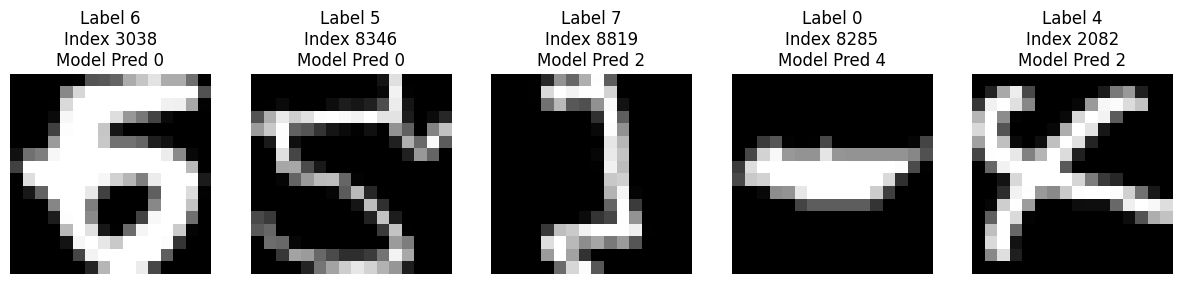

In [110]:
print('Q6')
fig, ax = plot_pixel_images(hard, hard_pred)
plt.show()
plt.close()

Q7

Gaussian kernel parameter choice: brief justification

Stage 1: Coarse scan
Test very wide values
c = {0.01, 0.1, 1, 10, 100, 1000, 10000}.
Only 0.01–1 behave sensibly; larger values collapse.
This identifies the correct order of magnitude.

Stage 2: Medium scan inside viable band
c = {0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1}.
Errors form a U-shape with the best region around 0.03–0.08.
This narrows the search to one small interval.

Stage 3: Log-scale refinement (base 2)
c = 2^{-k}, k = {3,4,5,6,7} → {0.125, 0.0625, 0.03125, 0.015625, 0.0078}.
Best results consistently around 0.03–0.06.

Final schedule for all experiments
Use a refined half-step grid:
c = 2^{-b/2}, b = 6…12 → {0.125, 0.088, 0.0625, 0.044, 0.031, 0.022, 0.0156}.
This covers the optimal region with good resolution and low cost.

Summary
A 3-stage search (coarse → medium → log-scale) showed the optimal Gaussian parameter lies around 0.03–0.06.
Therefore the final grid c = 2^{-b/2}, b = 6…12 was adopted for all later experiments.

(b) k class classifier one vs rest with Guassian kernel averaged over 20 runs

In [111]:
print('(b)')
runs = 20
# c= np.linspace(0.045, 0.055, 50).tolist()
c = [2**(-b/2) for b in range(6, 13)]
Classes = [0,1,2,3,4,5,6,7,8,9]
start = time.time()
avgme_df, _ , _ = r_sims_k_class_ker_perc(df, runs, Classes, param=c, kernel_func=guass_kern, split=rsplits)
end = time.time()
print(f"\nTotal runtime = {end - start:.2f} seconds ({(end-start)/60:.2f} minutes)")
print('K class kernel perceptron classifier, one vs rest')
print(f'Guassian Kernel : {runs} runs')
print(avgme_df)

(b)

Total runtime = 1226.96 seconds (20.45 minutes)
K class kernel perceptron classifier, one vs rest
Guassian Kernel : 20 runs
      param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0  0.125000      0.028680     0.069839         0.000541        0.006496
1  0.088388      0.026295     0.061317         0.000447        0.007988
2  0.062500      0.023373     0.054543         0.000423        0.005604
3  0.044194      0.020608     0.046156         0.000441        0.005096
4  0.031250      0.018647     0.041989         0.000407        0.004705
5  0.022097      0.017662     0.036532         0.000373        0.004516
6  0.015625      0.017834     0.037124         0.000392        0.004920


(c) Cross Validation of k class classifier one vs rest with Guassian kernel using 5 folds

In [112]:
print('(c)')
runs = 20
# c= np.linspace(0.045, 0.055, 50).tolist()
c = [2**(-b/2) for b in range(6, 13)]
Classes = [0,1,2,3,4,5,6,7,8,9]
start = time.time()
avgme_df, avgconfMatrix, hard, hard_pred = r_sims_k_class_ker_perc(df, runs, Classes, param=c, kernel_func=guass_kern, split=rsplits, crossVal=True, confusion=True)
end = time.time()
print(f"\nTotal runtime = {end - start:.2f} seconds ({(end-start)/60:.2f} minutes)")
print('K class kernel perceptron classifier, one vs rest')
print(f'Guassian Kernel : {runs} runs with cross validation')
print(avgme_df)

(c)

Total runtime = 3443.64 seconds (57.39 minutes)
K class kernel perceptron classifier, one vs rest
Guassian Kernel : 20 runs with cross validation
      param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0  0.022097      0.017751     0.036156         0.000343        0.004178


Confusion Matrix of k class classifier one vs rest with Guassian kernel and 5 fold cross validation averaged over 20 runs

In [113]:
print('Average Confusion Matrix')
avgconfMatrix = confusion_matrix_df(avgconfMatrix, Classes)
print(avgconfMatrix)

Average Confusion Matrix
                         0                        1                        2  \
0                  0.0±0.0  1.768x10-03±2.546x10-03  2.276x10-03±2.751x10-03   
1                  0.0±0.0                  0.0±0.0  7.366x10-04±2.526x10-03   
2   6.011x10-03±4.85x10-03  4.132x10-03±4.975x10-03                  0.0±0.0   
3  1.979x10-03±4.343x10-03   2.063x10-03±3.81x10-03   5.84x10-03±5.862x10-03   
4   2.067x10-03±3.46x10-03  6.445x10-03±6.961x10-03   5.265x10-03±6.05x10-03   
5  1.017x10-02±1.169x10-02  1.722x10-03±3.654x10-03   3.84x10-03±5.323x10-03   
6  8.832x10-03±8.984x10-03  4.204x10-03±5.868x10-03  2.924x10-03±4.576x10-03   
7                  0.0±0.0  3.238x10-03±5.394x10-03   9.367x10-03±1.02x10-02   
8   8.601x10-03±4.25x10-03   5.005x10-03±6.67x10-03   5.593x10-03±7.75x10-03   
9    1.525x10-03±3.3x10-03   2.48x10-03±4.552x10-03  2.112x10-03±3.951x10-03   

                         3                        4                        5  \
0  3.828x10-03

5 Hard to Predict Samples : k class classifier one vs rest with Guassian kernel and 5 fold cross validation averaged over 20 runs

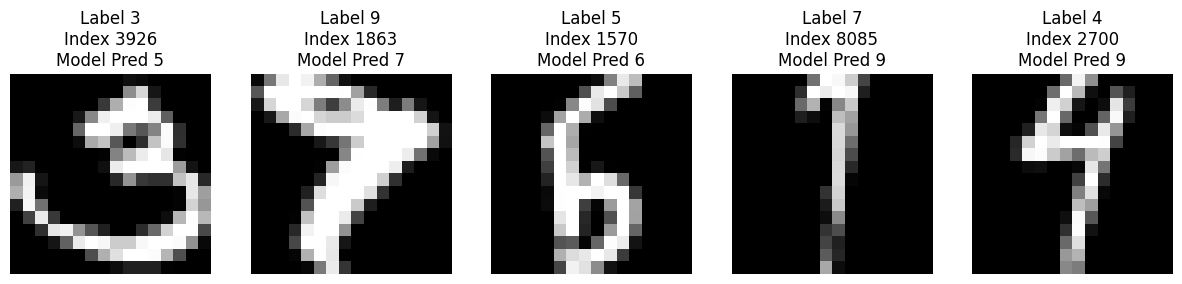

In [114]:
fig, ax = plot_pixel_images(hard, hard_pred)
plt.show()
plt.close()

Q8

(a). Research and explain how this method works. One vs One

(b) k class classifier one vs one with polynomial kernel averaged over 20 runs

In [115]:
print('(b)')
runs = 20
d=[1,2,3,4,5,6,7]
Classes = [0,1,2,3,4,5,6,7,8,9]
start = time.time()
avgme_df, _, _ = r_sims_k_class_ker_perc(df, runs, Classes, param=d, algorithm_func=k_class_one_vs_one_ker_perc, split=rsplits)
end = time.time()
print(f"\nTotal runtime = {end - start:.2f} seconds ({(end-start)/60:.2f} minutes)")
print('K class kernel perceptron classifier, one vs one')
print(f'Polynomial Kernel : {runs} runs')
print(avgme_df)

(b)

Total runtime = 413.30 seconds (6.89 minutes)
K class kernel perceptron classifier, one vs one
Polynomial Kernel : 20 runs
   param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0      1      0.038053     0.094059         0.000673        0.014776
1      2      0.028510     0.065376         0.000622        0.011848
2      3      0.025590     0.054973         0.000421        0.005590
3      4      0.024324     0.050995         0.000462        0.005489
4      5      0.024164     0.052016         0.000455        0.004628
5      6      0.024331     0.049785         0.000474        0.006371
6      7      0.024759     0.050376         0.000328        0.005092


(c) Cross Validation of k class classifier one vs one with polynomial kernel using 5 folds

In [116]:
print('(c)')
runs = 20
d=[1,2,3,4,5,6,7]
Classes = [0,1,2,3,4,5,6,7,8,9]
start = time.time()
avgme_df, avgconfMatrix, hard, hard_pred = r_sims_k_class_ker_perc(df, runs, Classes, param=d, algorithm_func=k_class_one_vs_one_ker_perc, split=rsplits, crossVal=True, confusion=True)
end = time.time()
print(f"\nTotal runtime = {end - start:.2f} seconds ({(end-start)/60:.2f} minutes)")
print('K class kernel perceptron classifier, one vs one')
print(f'Polynomial Kernel : {runs} runs with cross validation')
print(avgme_df)

(c)


UnboundLocalError: cannot access local variable 'K_full_train' where it is not associated with a value

Confusion Matrix of k class classifier one vs one with polynomial kernel and 5 fold cross validation averaged over 20 runs

In [ ]:
print('Average Confusion Matrix')
avgconfMatrix = confusion_matrix_df(avgconfMatrix, Classes)
print(avgconfMatrix)

5 Hard to Predict Samples : k class classifier one vs rest with polynomial kernel and 5 fold cross validation averaged over 20 runs

In [ ]:
fig, ax = plot_pixel_images(hard, hard_pred)
plt.show()
plt.close()

EXTENSION : k class classifier one vs one with Guassian kernel averaged over 20 runs

In [ ]:
runs = 20
c = [2**(-b/2) for b in range(6, 13)]
Classes = [0,1,2,3,4,5,6,7,8,9]
start = time.time()
avgme_df, _, _ = r_sims_k_class_ker_perc(df, runs, Classes, param=c, algorithm_func=k_class_one_vs_one_ker_perc, kernel_func=guass_kern, split=rsplits)
end = time.time()
print(f"\nTotal runtime = {end - start:.2f} seconds ({(end-start)/60:.2f} minutes)")
print('K class kernel perceptron classifier, one vs one')
print(f'Guassian Kernel : {runs} runs')
print(avgme_df)

Cross Validation of k class classifier one vs one with Guassian kernel using 5 folds

In [ ]:
runs = 20
c = [2**(-b/2) for b in range(6, 13)]
Classes = [0,1,2,3,4,5,6,7,8,9]
start = time.time()
avgme_df, avgconfMatrix, hard, hard_pred = r_sims_k_class_ker_perc(df, runs, Classes, param=c, algorithm_func=k_class_one_vs_one_ker_perc, kernel_func=guass_kern, split=rsplits, crossVal=True, confusion=True)
end = time.time()
print(f"\nTotal runtime = {end - start:.2f} seconds ({(end-start)/60:.2f} minutes)")
print('K class kernel perceptron classifier, one vs one')
print(f'Guassian Kernel : {runs} runs with cross validation')
print(avgme_df)

Confusion Matrix of k class classifier one vs one with Guassian kernel and 5 fold cross validation averaged over 20 runs

In [ ]:
print('Average Confusion Matrix')
avgconfMatrix = confusion_matrix_df(avgconfMatrix, Classes)
print(avgconfMatrix)

5 Hard to Predict Samples : k class classifier one vs one with Guassian kernel and 5 fold cross validation averaged over 20 runs

In [ ]:
fig, ax = plot_pixel_images(hard, hard_pred)
plt.show()
plt.close()

(d). Include a discussion comparing the results for the ‘One-versus-One’ method to the results for the
‘One-versus-Rest’ method (both with polynomial kernel).

20